In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.feature_selection import SelectKBest, mutual_info_classif, RFECV
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    average_precision_score, brier_score_loss, f1_score, recall_score, precision_score
)

# Algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# --- Load Data & Define Zero-Coded Missing Features ---
df = pd.read_csv('diabetes.csv')

# Standard column mapping
cols_with_impossible_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
target_col = 'Outcome'

# Replace biologically impossible zeros with NaN
df_cleaned = df.copy()
df_cleaned[cols_with_impossible_zeros] = df_cleaned[cols_with_impossible_zeros].replace(0, np.nan)

# Data Dictionary / Profiling Summary
data_dict = pd.DataFrame({
    'Feature': df_cleaned.columns,
    'Dtype': df_cleaned.dtypes.values,
    'Missing_Count': df_cleaned.isnull().sum().values,
    'Missing_Pct (%)': (df_cleaned.isnull().mean() * 100).round(2).values,
    'Min_Observed': df_cleaned.min().values,
    'Max_Observed': df_cleaned.max().values
})
print("=== Step 1: Data Profiling & Null Summary ===")
print(data_dict.to_string(index=False))

# Separate features and target
df_cleaned = df_cleaned.dropna(subset=[target_col])
X = df_cleaned.drop(columns=[target_col])
y = df_cleaned[target_col].map({'tested_negative': 0, 'tested_positive': 1}).astype(int)  # Ensure binary encoding

# Stratified Holdout Split (80/20) - Fit only on Train to prevent leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

=== Step 1: Data Profiling & Null Summary ===
                 Feature   Dtype  Missing_Count  Missing_Pct (%)    Min_Observed    Max_Observed
             Pregnancies   int64              0             0.00               0              17
                 Glucose float64              5             0.65            44.0           199.0
           BloodPressure float64             35             4.56            24.0           122.0
           SkinThickness float64            227            29.56             7.0            99.0
                 Insulin float64            374            48.70            14.0           846.0
                     BMI float64             11             1.43            18.2            67.1
DiabetesPedigreeFunction float64              0             0.00           0.078            2.42
                     Age   int64              0             0.00              21              81
                 Outcome  object              0             0.00 tested_negative 

C:\Users\krisha goti\AppData\Local\Temp\ipykernel_19180\1778554095.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=target, data=data, palette='Set2',legend=False)


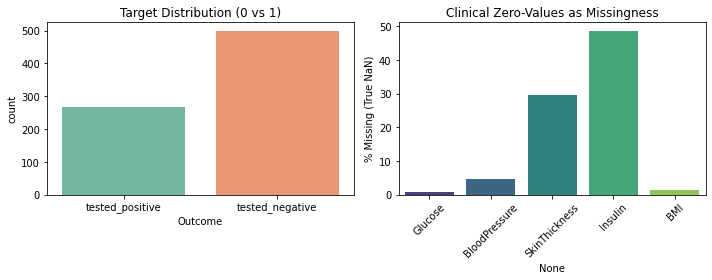

In [21]:
def plot_eda(data, target):
    plt.figure(figsize=(10, 4))
    
    # Target Distribution
    plt.subplot(1, 2, 1)
    sns.countplot(x=target, data=data, palette='Set2',legend=False)
    plt.title("Target Distribution (0 vs 1)")
    
    # Missingness across clinical features
    plt.subplot(1, 2, 2)
    missing_pct = data[cols_with_impossible_zeros].isnull().mean() * 100
    sns.barplot(x=missing_pct.index, y=missing_pct.values, palette='viridis',hue=missing_pct.index,legend=False) 
    plt.ylabel('% Missing (True NaN)')
    plt.xticks(rotation=45)
    plt.title("Clinical Zero-Values as Missingness")
    plt.tight_layout()
    plt.show()

# Run EDA
plot_eda(df_cleaned, target_col)

In [22]:
# Function for safe log-transform of skewed variables like Insulin
def log_transform(x):
    return np.log1p(np.clip(x, 0, None))

# Define candidate models
base_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Gaussian NB': GaussianNB(),
    'SVM (RBF)': SVC(probability=True, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'KNN': KNeighborsClassifier()
}

# Preprocessing Pipelines
# Arm A: Median Imputer + StandardScaler
pipe_arm_a = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Arm B: KNN Multivariate Imputer + RobustScaler + Log-transform
pipe_arm_b = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('log_skewed', FunctionTransformer(log_transform)),
    ('scaler', RobustScaler())
])

# Arm C: Median Imputer with MissingIndicator + StandardScaler
pipe_arm_c = Pipeline([
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])

preprocessing_arms = {
    'Arm A (Median + Standard)': pipe_arm_a,
    'Arm B (KNN + Log + Robust)': pipe_arm_b,
    'Arm C (Median + Indicator)': pipe_arm_c
}

scoring_metrics = ['roc_auc', 'recall', 'f1']
comparison_results = []

for arm_name, preprocessor in preprocessing_arms.items():
    for model_name, model in base_models.items():
        pipeline = Pipeline([
            ('preprocess', preprocessor),
            ('model', model)
        ])
        cv_res = cross_validate(pipeline, X_train, y_train, cv=cv_strat, scoring=scoring_metrics)
        comparison_results.append({
            'Preprocessing Arm': arm_name,
            'Model': model_name,
            'ROC-AUC': np.mean(cv_res['test_roc_auc']),
            'Recall': np.mean(cv_res['test_recall']),
            'F1': np.mean(cv_res['test_f1'])
        })

df_arm_comp = pd.DataFrame(comparison_results)
print("\n=== Step 4: Preprocessing Arm Comparison (Cross-Validated Means) ===")
print(df_arm_comp.sort_values(by='ROC-AUC', ascending=False).head(10).to_string(index=False))


=== Step 4: Preprocessing Arm Comparison (Cross-Validated Means) ===
         Preprocessing Arm               Model  ROC-AUC   Recall       F1
 Arm A (Median + Standard) Logistic Regression 0.843364 0.574751 0.654545
Arm B (KNN + Log + Robust) Logistic Regression 0.843170 0.598117 0.659459
Arm C (Median + Indicator) Logistic Regression 0.838515 0.598117 0.664962
Arm B (KNN + Log + Robust)         Gaussian NB 0.835594 0.696678 0.655166
 Arm A (Median + Standard)           SVM (RBF) 0.833308 0.584164 0.648462
Arm C (Median + Indicator)           SVM (RBF) 0.832623 0.565559 0.629536
 Arm A (Median + Standard)         Gaussian NB 0.828128 0.598450 0.636877
Arm B (KNN + Log + Robust)       Random Forest 0.823511 0.570100 0.622447
Arm B (KNN + Log + Robust)           SVM (RBF) 0.819617 0.588926 0.648885
Arm C (Median + Indicator)       Random Forest 0.816859 0.579734 0.631764


In [23]:
# 1. Feature Engineering Transformer
class MedicalFeatureEngineering:
    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        X_out = X.copy()
        # Glucose to Insulin ratio (measure of insulin sensitivity/resistance indicator)
        X_out['Glucose_Insulin_Ratio'] = X_out['Glucose'] / (X_out['Insulin'] + 1e-5)
        # Metabolic syndrome risk proxy flags (binary indicators)
        X_out['High_Glucose'] = (X_out['Glucose'] > 140).astype(int)
        X_out['Obese'] = (X_out['BMI'] >= 30.0).astype(int)
        return X_out

fe_pipeline = Pipeline([
    ('fe', MedicalFeatureEngineering()),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 2. Track Performance vs Number of Features via Mutual Information
X_train_fe = fe_pipeline.fit_transform(X_train)
k_values = list(range(3, X_train_fe.shape[1] + 1))
k_scores = []

for k in k_values:
    selector = SelectKBest(score_func=mutual_info_classif, k=k)
    clf = RandomForestClassifier(random_state=42)
    pipeline = Pipeline([('select', selector), ('clf', clf)])
    scores = cross_validate(pipeline, X_train_fe, y_train, cv=cv_strat, scoring='roc_auc')
    k_scores.append(np.mean(scores['test_score']))

optimal_k = k_values[np.argmax(k_scores)]
print(f"\n=== Step 5: Feature Selection Analysis ===")
print(f"Optimal number of features via Mutual Information: {optimal_k} (ROC-AUC: {max(k_scores):.4f})")


=== Step 5: Feature Selection Analysis ===
Optimal number of features via Mutual Information: 10 (ROC-AUC: 0.8200)


In [24]:
# Build end-to-end tuning pipeline with optimal preprocessing
base_pipeline = Pipeline([
    ('preprocess', pipe_arm_a),
    ('select', SelectKBest(score_func=mutual_info_classif, k=8)),
    ('model', None)
])

param_grids = {
    'Logistic Regression': {
        'model': [LogisticRegression(solver='liblinear', random_state=42)],
        'model__C': [0.01, 0.1, 1.0, 10.0],
        'model__penalty': ['l1', 'l2']
    },
    'SVM (RBF)': {
        'model': [SVC(probability=True, random_state=42)],
        'model__C': [0.1, 1.0, 5.0],
        'model__gamma': ['scale', 'auto', 0.01]
    },
    'Random Forest': {
        'model': [RandomForestClassifier(random_state=42)],
        'model__n_estimators': [100, 200],
        'model__max_depth': [3, 5, 8, None],
        'model__min_samples_split': [2, 5]
    },
    'KNN': {
        'model': [KNeighborsClassifier()],
        'model__n_neighbors': [3, 5, 9, 15],
        'model__weights': ['uniform', 'distance']
    },
    'Gaussian NB': {
        'model': [GaussianNB()],
        'model__var_smoothing': np.logspace(-9, -2, 8)
    }
}

best_estimators = {}

print("\n=== Step 6: Hyperparameter Tuning ===")
for name, p_grid in param_grids.items():
    grid = GridSearchCV(base_pipeline, p_grid, cv=cv_strat, scoring='roc_auc', n_jobs=-1)
    grid.fit(X_train, y_train)
    best_estimators[name] = grid.best_estimator_
    print(f"{name:20} -> Best CV ROC-AUC: {grid.best_score_:.4f} | Params: {grid.best_params_}")


=== Step 6: Hyperparameter Tuning ===
Logistic Regression  -> Best CV ROC-AUC: 0.8439 | Params: {'model': LogisticRegression(random_state=42, solver='liblinear'), 'model__C': 0.1, 'model__penalty': 'l2'}
SVM (RBF)            -> Best CV ROC-AUC: 0.8463 | Params: {'model': SVC(probability=True, random_state=42), 'model__C': 1.0, 'model__gamma': 0.01}
Random Forest        -> Best CV ROC-AUC: 0.8391 | Params: {'model': RandomForestClassifier(random_state=42), 'model__max_depth': 5, 'model__min_samples_split': 5, 'model__n_estimators': 200}
KNN                  -> Best CV ROC-AUC: 0.8328 | Params: {'model': KNeighborsClassifier(), 'model__n_neighbors': 15, 'model__weights': 'distance'}
Gaussian NB          -> Best CV ROC-AUC: 0.8282 | Params: {'model': GaussianNB(), 'model__var_smoothing': 0.01}


In [25]:
print("\n=== Step 7: Research Extensions ===")

# 1. Class Weighting Impact (Logistic Regression)
for weight in [None, 'balanced']:
    lr_weighted = Pipeline([
        ('preprocess', pipe_arm_a),
        ('model', LogisticRegression(class_weight=weight, random_state=42))
    ])
    cv_res = cross_validate(lr_weighted, X_train, y_train, cv=cv_strat, scoring=['recall', 'precision', 'f1'])
    print(f"LR class_weight={str(weight):8} | Recall: {np.mean(cv_res['test_recall']):.3f} | Precision: {np.mean(cv_res['test_precision']):.3f} | F1: {np.mean(cv_res['test_f1']):.3f}")

# 2. Probability Calibration (Gaussian Naive Bayes)
gnb_model = best_estimators['Gaussian NB']
gnb_model.fit(X_train, y_train)
calibrated_gnb = CalibratedClassifierCV(gnb_model, method='sigmoid', cv='prefit')
calibrated_gnb.fit(X_train, y_train)

# Evaluate Brier Score on Test Set
y_prob_uncal = gnb_model.predict_proba(X_test)[:, 1]
y_prob_cal = calibrated_gnb.predict_proba(X_test)[:, 1]

print(f"Gaussian NB Brier Score (Uncalibrated): {brier_score_loss(y_test, y_prob_uncal):.4f}")
print(f"Gaussian NB Brier Score (Calibrated)  : {brier_score_loss(y_test, y_prob_cal):.4f}")

# 3. Subgroup Fairness/Performance Check (Age < 30 vs Age >= 30)
rf_best = best_estimators['Random Forest']
rf_best.fit(X_train, y_train)
test_predictions = rf_best.predict(X_test)

test_eval_df = X_test.copy()
test_eval_df['True_Outcome'] = y_test
test_eval_df['Pred_Outcome'] = test_predictions

for group_name, group_data in [('Younger (<30)', test_eval_df[test_eval_df['Age'] < 30]),
                               ('Older (>=30)', test_eval_df[test_eval_df['Age'] >= 30])]:
    rec = recall_score(group_data['True_Outcome'], group_data['Pred_Outcome'])
    prec = precision_score(group_data['True_Outcome'], group_data['Pred_Outcome'], zero_division=0)
    print(f"Subgroup {group_name:15} | Sample Size: {len(group_data)} | Recall: {rec:.3f} | Precision: {prec:.3f}")


=== Step 7: Research Extensions ===
LR class_weight=None     | Recall: 0.575 | Precision: 0.764 | F1: 0.655
LR class_weight=balanced | Recall: 0.701 | Precision: 0.649 | F1: 0.672
Gaussian NB Brier Score (Uncalibrated): 0.2285
Gaussian NB Brier Score (Calibrated)  : 0.1995
Subgroup Younger (<30)   | Sample Size: 85 | Recall: 0.312 | Precision: 0.417
Subgroup Older (>=30)    | Sample Size: 69 | Recall: 0.605 | Precision: 0.767



=== Step 8: Final Evaluation on Hold-Out Test Set ===
              Model  Precision   Recall  F1-Score  ROC-AUC   PR-AUC  Brier Score
        Gaussian NB   0.566667 0.629630  0.596491 0.764815 0.596209     0.228519
                KNN   0.644444 0.537037  0.585859 0.806852 0.675236     0.169674
Logistic Regression   0.583333 0.518519  0.549020 0.809815 0.664707     0.173215
      Random Forest   0.666667 0.518519  0.583333 0.807037 0.687341     0.169030
          SVM (RBF)   0.609756 0.462963  0.526316 0.805185 0.675695     0.174843


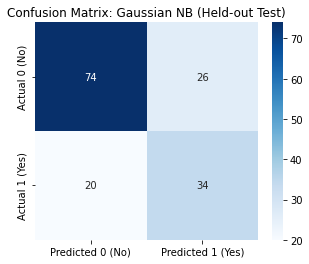

In [26]:
print("\n=== Step 8: Final Evaluation on Hold-Out Test Set ===")
final_metrics = []

for name, model in best_estimators.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    final_metrics.append({
        'Model': name,
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'PR-AUC': average_precision_score(y_test, y_proba),
        'Brier Score': brier_score_loss(
            y_test, y_proba)
    })

df_final = pd.DataFrame(final_metrics).sort_values(by='Recall', ascending=False)
print(df_final.to_string(index=False))

# Confusion Matrix for Top Model (prioritizing Recall in medical diagnostic screening)
best_model_name = df_final.iloc[0]['Model']
best_model = best_estimators[best_model_name]
cm = confusion_matrix(y_test, best_model.predict(X_test))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0 (No)', 'Predicted 1 (Yes)'],
            yticklabels=['Actual 0 (No)', 'Actual 1 (Yes)'])
plt.title(f"Confusion Matrix: {best_model_name} (Held-out Test)")
plt.show()